In [ ]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import matplotlib.pyplot as plt

from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

Matplotlib is building the font cache; this may take a moment.


In [2]:
''' FOR KAGGLE NOTEBOOK '''
#  Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

''' FOR JUPYTER NOTEBOOK '''
import kagglehub
path = kagglehub.competition_download('ieee-fraud-detection')

print("Path to competition files:", path)


Path to competition files: /Users/eric/.cache/kagglehub/competitions/ieee-fraud-detection


In [3]:
import os
for dirname, _, filenames in os.walk(path):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/Users/eric/.cache/kagglehub/competitions/ieee-fraud-detection/test_transaction.csv
/Users/eric/.cache/kagglehub/competitions/ieee-fraud-detection/train_identity.csv
/Users/eric/.cache/kagglehub/competitions/ieee-fraud-detection/test_identity.csv
/Users/eric/.cache/kagglehub/competitions/ieee-fraud-detection/sample_submission.csv
/Users/eric/.cache/kagglehub/competitions/ieee-fraud-detection/train_transaction.csv


In [4]:
train_id = pd.read_csv(f'{path}/train_identity.csv')
train_tr = pd.read_csv(f'{path}/train_transaction.csv')
# test_id = pd.read_csv(f'{path}/test_identity.csv')
# test_tr = pd.read_csv(f'{path}/test_transaction.csv')

In [74]:
print("Number of training samples:", len(train_tr))
print(f"Proportion of fraudulent samples: {train_tr['isFraud'].mean():.4f}")

Number of training samples: 590540
Proportion of fraudulent samples: 0.0350


In [5]:
train_tr.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
train_id.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [7]:
# merge id and transaction data
train = pd.merge(train_tr, train_id, on='TransactionID', how='left')

In [8]:
# drop columns with high nan frequency?
# nan_frequency = train.isna().mean()
# train = train.loc[:, nan_frequency < 0.99]

## Encoding Categorical Variables

In [9]:
# Show unique values for categorical features
categories_tr = ['ProductCD', 'addr1', 'addr2', 'P_emaildomain', 'R_emaildomain'] 
categories_tr += [f'card{n}' for n in range(1, 7)] + [f'M{n}' for n in range(1,10)]
categories_id = ['DeviceType', 'DeviceInfo'] + [f'id_{n}' for n in range(12,39)]
categories = categories_tr + categories_id
num_values = train[categories].nunique()
num_values

ProductCD            5
addr1              332
addr2               74
P_emaildomain       59
R_emaildomain       60
card1            13553
card2              500
card3              114
card4                4
card5              119
card6                4
M1                   2
M2                   2
M3                   2
M4                   3
M5                   2
M6                   2
M7                   2
M8                   2
M9                   2
DeviceType           2
DeviceInfo        1786
id_12                2
id_13               54
id_14               25
id_15                3
id_16                2
id_17              104
id_18               18
id_19              522
id_20              394
id_21              490
id_22               25
id_23                3
id_24               12
id_25              341
id_26               95
id_27                2
id_28                2
id_29                2
id_30               75
id_31              130
id_32                4
id_33      

In [10]:
binary_categories = [cat for cat in categories if num_values[cat] == 2]
# use one hot encoding when number of unique values is between 3 and 5
onehot_categories = [cat for cat in categories if num_values[cat] > 2 and num_values[cat] <= 5]
# otherwise use label or frequency encoding
numerous_categories = [cat for cat in categories if num_values[cat] > 5]

print('Binary categories:', binary_categories)
print('One-hot categories:', onehot_categories)
print('Numerous categories:', numerous_categories)

Binary categories: ['M1', 'M2', 'M3', 'M5', 'M6', 'M7', 'M8', 'M9', 'DeviceType', 'id_12', 'id_16', 'id_27', 'id_28', 'id_29', 'id_35', 'id_36', 'id_37', 'id_38']
One-hot categories: ['ProductCD', 'card4', 'card6', 'M4', 'id_15', 'id_23', 'id_32', 'id_34']
Numerous categories: ['addr1', 'addr2', 'P_emaildomain', 'R_emaildomain', 'card1', 'card2', 'card3', 'card5', 'DeviceInfo', 'id_13', 'id_14', 'id_17', 'id_18', 'id_19', 'id_20', 'id_21', 'id_22', 'id_24', 'id_25', 'id_26', 'id_30', 'id_31', 'id_33']


In [11]:
for cat in onehot_categories:
    print(cat)
    print(train[cat].unique())

ProductCD
<StringArray>
['W', 'H', 'C', 'S', 'R']
Length: 5, dtype: str
card4
<StringArray>
['discover', 'mastercard', 'visa', 'american express', nan]
Length: 5, dtype: str
card6
<StringArray>
['credit', 'debit', nan, 'debit or credit', 'charge card']
Length: 5, dtype: str
M4
<StringArray>
['M2', 'M0', nan, 'M1']
Length: 4, dtype: str
id_15
<StringArray>
[nan, 'New', 'Found', 'Unknown']
Length: 4, dtype: str
id_23
<StringArray>
[nan, 'IP_PROXY:TRANSPARENT', 'IP_PROXY:ANONYMOUS', 'IP_PROXY:HIDDEN']
Length: 4, dtype: str
id_32
[nan 32. 24. 16.  0.]
id_34
<StringArray>
[nan, 'match_status:2', 'match_status:1', 'match_status:0', 'match_status:-1']
Length: 5, dtype: str


In [12]:
oe = OrdinalEncoder()
train[binary_categories] = oe.fit_transform(train[binary_categories])
train[binary_categories].head()

,M1,M2,M3,M5,M6,M7,M8,M9,DeviceType,id_12,id_16,id_27,id_28,id_29,id_35,id_36,id_37,id_38
0,1.0,1.0,1.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,1.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,1.0,NaN,1.0,1.0,1.0,0.0,1.0,1.0


In [13]:
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
ohe.fit(train[onehot_categories])

def ohe_transform(df, categories, ohe):
    encoded_array = ohe.transform(df[categories])
    encoded_df = pd.DataFrame(encoded_array, columns=ohe.get_feature_names_out(categories))
    return pd.concat([df.drop(columns=categories), encoded_df], axis=1)

train = ohe_transform(train, onehot_categories, ohe)
train.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,...,id_32_0.0,id_32_16.0,id_32_24.0,id_32_32.0,id_32_nan,id_34_match_status:-1,id_34_match_status:0,id_34_match_status:1,id_34_match_status:2,id_34_nan
0,2987000,0,86400,68.5,13926,NaN,150.0,142.0,315.0,87.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,2987001,0,86401,29.0,2755,404.0,150.0,102.0,325.0,87.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,2987002,0,86469,59.0,4663,490.0,150.0,166.0,330.0,87.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,2987003,0,86499,50.0,18132,567.0,150.0,117.0,476.0,87.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,2987004,0,86506,50.0,4497,514.0,150.0,102.0,420.0,87.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [14]:
# let's do a frequency encoding for the rest
freq_map = {}
for cat in numerous_categories:
    freq_dict = train[cat].value_counts(normalize=True).to_dict()
    train[cat] = train[cat].map(freq_dict)
    freq_map[cat] = freq_dict

train[numerous_categories].head()
    

,addr1,addr2,P_emaildomain,R_emaildomain,card1,card2,card3,card5,DeviceInfo,id_13,...,id_19,id_20,id_21,id_22,id_24,id_25,id_26,id_30,id_31,id_33
0,0.043972,0.991706,NaN,NaN,0.000073,NaN,0.885075,0.000472,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.081456,0.991706,0.460315,NaN,0.001157,0.005254,0.885075,0.049643,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.050086,0.991706,0.010272,NaN,0.001876,0.065586,0.885075,0.097462,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.018059,0.991706,0.203462,NaN,0.007127,0.010552,0.885075,0.044247,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.006823,0.991706,0.460315,NaN,0.000030,0.025001,0.885075,0.049643,0.000076,NaN,...,0.036722,0.004847,NaN,NaN,NaN,NaN,NaN,0.037014,0.007563,0.007423


In [15]:
# given oe, ohe, and freq_dict, apply all encoding transformations to df
def transform(df):
    df[binary_categories] = oe.transform(df[binary_categories])
    df = ohe_transform(df, onehot_categories, ohe)
    for cat in numerous_categories:
        df[cat] = df[cat].map(freq_dict[cat])
    return df

## Training and Validation

Given the large frequency of missing data fields, we'll use XGBoost to classify. Maybe compare with Random Forest. 

For splitting into training and validation sets, we use a cutoff in time since the data is ordered with respect to time, in order to avoid any data leakage.

In [37]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve

In [17]:
# split into training and validation sets
N_valid = int(0.2 * len(train))
train_ = train.iloc[:(-N_valid)]
validation = train.iloc[(-N_valid):]

## Single Decision Tree

In [18]:
y_train = train_[['isFraud']]
X_train = train_.drop(columns=['isFraud'])
y_valid = validation[['isFraud']]
X_valid = validation.drop(columns=['isFraud'])

In [57]:
tree_classifier = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5
).fit(X_train, y_train)

Accuracy: 0.9761
Precision: 0.9099
Recall: 0.3548
F1 Score: 0.5105
ROC AUC: 0.8209


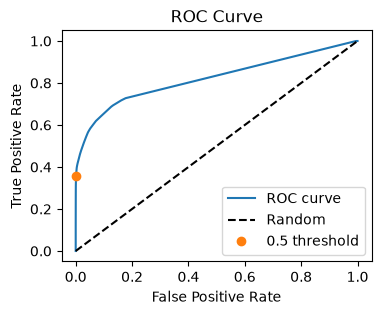

Accuracy: 0.9667
Precision: 0.5590
Recall: 0.1528
F1 Score: 0.2400
ROC AUC: 0.7735


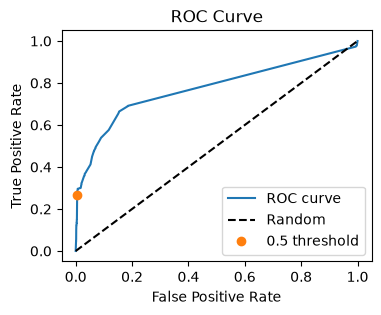

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

def print_metrics(X, y, classifier):
    y_pred = classifier.predict(X)
    y_score = classifier.predict_proba(X)[:, 1]
    print(f"Accuracy: {accuracy_score(y, y_pred):.4f}")
    print(f"Precision: {precision_score(y, y_pred):.4f}")
    print(f"Recall: {recall_score(y, y_pred):.4f}")
    print(f"F1 Score: {f1_score(y, y_pred):.4f}")

    print(f"ROC AUC: {roc_auc_score(y, y_score):.4f}")

    fpr, tpr, thresholds = roc_curve(y, y_score)
    idx = np.where(thresholds == 0.5)[0]
    plt.figure(figsize=(4, 3))
    plt.plot(fpr, tpr, label='ROC curve')
    plt.plot([0, 1], [0, 1], 'k--', label='Random')
    plt.plot(fpr[idx], tpr[idx], 'o', label='0.5 threshold')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()
    plt.show()

print_metrics(X_train, y_train, tree_classifier)

print_metrics(X_valid, y_valid, tree_classifier)


### How did a single decision tree perform?

When looking only at accuracy, the classifier seems to perform decently well at 97.6%, and this generalizes well to 96.7% on the validation set. However, accuracy ignores the class imbalance: fraudulent samples make up only ~3.5% of the training set. 

On training, precision is 91% and recall is 35%. That is, 91% of the samples the model detected as fraud were actually fraudulent, though only 35% of all the fradulent samples were detected correctly. While precision seems pretty good on training, the precision is only 56% on the validation set, suggesting overfitting on the fraudulent samples in the training set. 

To combat overfitting, let's consider a Random Forest. From statistical learning theory, these should capture roughly the same amount of bias as a single decision tree, but with lower variance due to the individual trees having low correlation.

## Random Forest

In [83]:
rf_classifier = RandomForestClassifier(
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5
).fit(X_train, y_train)

/Users/eric/projects/kaggle/.venv/lib/python3.14/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Accuracy: 0.9799
Precision: 0.9824
Recall: 0.4347
F1 Score: 0.6027
ROC AUC: 0.9405


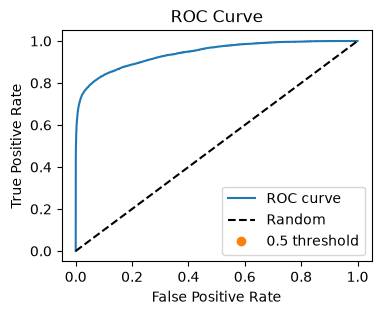

Accuracy: 0.9735
Precision: 0.8311
Recall: 0.2881
F1 Score: 0.4279
ROC AUC: 0.8793


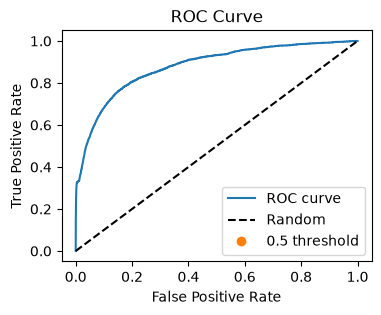

In [85]:
print_metrics(X_train, y_train, rf_classifier)

print_metrics(X_valid, y_valid, rf_classifier)

In [87]:
import xgboost as xgb

xgb_classifier = xgb.XGBClassifier(
    max_depth=10,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc'
).fit(X_train, y_train)

XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Users/eric/projects/kaggle/.venv/lib/python3.14/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <09B43001-8527-34F6-AAE4-B97DA8A6CBC0> /Users/eric/projects/kaggle/.venv/lib/python3.14/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libo